# $n$-step SARSA

In [2]:
import time 
import gymnasium as gym
from tqdm import tqdm  # tqdm es una libreria que muestra barra de progresos
import random
import numpy as np 
import matplotlib.pyplot as plt

print(gym.__version__)

1.3.0


In [5]:
# Crear ambiente 
env = gym.make('CliffWalking-v1', render_mode = 'human')
# Probando un episodio
observation, _ = env.reset() 
done = False
for _ in range(20):
    #Escoger una acción random
    action = env.action_space.sample()  
    #Usar la acción en el ambiente
    observation, reward, terminated, truncated, info = env.step(action) 
    done = terminated or truncated

#Cerrar el ambiente    
env.close()

In [6]:
class nstep_Sarsa:
    """ n-step Sarsa algorithm """
    def __init__(self, n, epsilon, epsilon_min, epsilon_decay, alpha, gamma, n_states, n_action):
        self.Q_table = np.zeros([n_states, n_action])
        self.n_action = n_action
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.n = n  # Usar algoritmo n-step Sarsa
        self.state_list = []  # guarar el estado previo
        self.action_list = []  # guardar las acciones previas
        self.reward_list = []  # guardar recompensas previas

    def take_action(self, state):
        if np.random.random() < self.epsilon:
            action = np.random.randint(self.n_action)
        else:
            action = np.argmax(self.Q_table[state])
        return action

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def best_action(self, state):  # para imprimir la estrategia
        Q_max = np.max(self.Q_table[state])
        a = [0 for _ in range(self.n_action)]
        for i in range(self.n_action):
            if self.Q_table[state, i] == Q_max:
                a[i] = 1
        return a

    def update(self, s0, a0, r, s1, a1, done):
        self.state_list.append(s0)
        self.action_list.append(a0)
        self.reward_list.append(r)
        if len(self.state_list) == self.n:  # Si los datos guardados pueden ser actualizados en n pasos
            G = self.Q_table[s1, a1]  # Obtener Q(s_{t+n}, a_{t+n})
            for i in reversed(range(self.n)):
                G = self.gamma * G + self.reward_list[i]  # Calcular la recompensa de cada paso continuamente
                # Si el estado terminal es alcanzado, los ultimos pasos seran actualizados updated a pesar que la longitud no es suficiente para n pasos
                if done and i > 0:
                    s = self.state_list[i]
                    a = self.action_list[i]
                    self.Q_table[s, a] += self.alpha * (G - self.Q_table[s, a])
            s = self.state_list.pop(0)  # Eliminar el estado-accion que necesita ser actualizado de la lista, no hay necesidad de actualizar en el siguiente paso
            a = self.action_list.pop(0)
            self.reward_list.pop(0)
            # n-step Sarsa actualizacion
            self.Q_table[s, a] += self.alpha * (G - self.Q_table[s, a])
        if done:  # Si el estado terminal es alcanzadod y la siguiente secuencia esta por empezar, la lista sera limpiada
            self.state_list = []
            self.action_list = []
            self.reward_list = []

Iteration 9: 100%|██████████| 200/200 [00:00<00:00, 2524.36it/s, episode=2000, return=-19.900, epsilon=0.010]


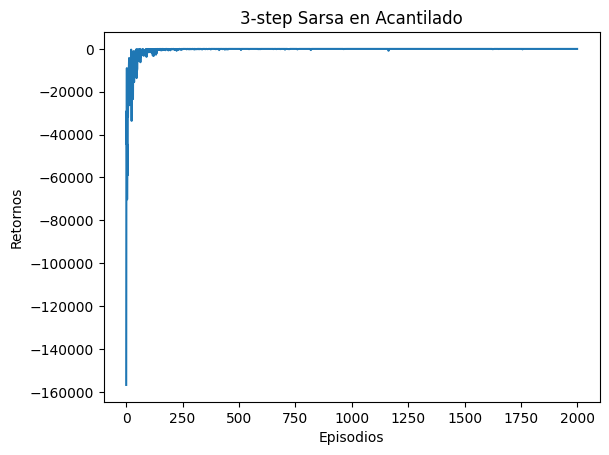

In [18]:
env = gym.make('CliffWalking-v1')

n_step = 3  # Algoritmo n-step Sarsa
n_states = env.observation_space.n
n_actions = env.action_space.n
np.random.seed(0)
epsilon = 1
epsilon_min = 0.01
epsilon_decay = 0.995
alpha = 0.5
gamma = 0.99
agent = nstep_Sarsa(n_step, epsilon, epsilon_min, epsilon_decay, alpha, gamma, n_states, n_actions)
num_episodes = 2000  # Numero de secuencias que el agente correra el ambiente

return_list = []  # Guardar el retorno de cada secuencia
for i in range(10):  # Mostrar 10 barras de progreso
    # La barra de progreso de la funcion tqdm
    with tqdm(total=int(num_episodes / 10), desc='Iteration %d' % i) as pbar:
        for i_episode in range(int(num_episodes / 10)):  # numero de secuencias para cada barra de progreso
            episode_return = 0
            state, _ = env.reset()
            action = agent.take_action(state)
            done = False
            while not done:
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated
                next_action = agent.take_action(next_state)
                episode_return += reward  
                agent.update(state,action,reward,next_state,next_action,done)
                state = next_state
                action = next_action
            agent.decay_epsilon()
            return_list.append(episode_return)
            if (i_episode + 1) % 10 == 0:  # Imprimir el retorno promedio
                pbar.set_postfix({
                    'episode':
                    '%d' % (num_episodes / 10 * i + i_episode + 1),
                    'return':
                    '%.3f' % np.mean(return_list[-10:]),
                    'epsilon':
                    '%.3f' % agent.epsilon
                })
            pbar.update(1)

episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title(f'{n_step}-step Sarsa en Acantilado')
plt.show()

In [19]:
def print_agent(agent, env, action_meaning, disaster=[], end=[]):
    for i in range(env.unwrapped.shape[0]):
        for j in range(env.env.unwrapped.shape[1]):
            if (i * env.unwrapped.shape[1] + j) in disaster:
                print('****', end=' ')
            elif (i * env.unwrapped.shape[1] + j) in end:
                print('EEEE', end=' ')
            else:
                a = agent.best_action(i * env.unwrapped.shape[1] + j)
                pi_str = ''
                for k in range(len(action_meaning)):
                    pi_str += action_meaning[k] if a[k] > 0 else 'o'
                print(pi_str, end=' ')
        print()

action_meaning = ['^', '>', 'v', '<']
print('La estrategia obtenida por el algoritmo de Sarsa es：')
print_agent(agent, env, action_meaning, list(range(37, 47)), [47])

La estrategia obtenida por el algoritmo de Sarsa es：
o>oo o>oo o>oo oovo o>oo o>oo o>oo o>oo o>oo oovo o>oo oovo 
^ooo ooo< o>oo o>oo ^ooo ^ooo ^ooo ^ooo ^ooo o>oo o>oo oovo 
^ooo o>oo ^ooo ^ooo ^ooo ^ooo ^ooo o>oo ^ooo ^ooo o>oo oovo 
^ooo **** **** **** **** **** **** **** **** **** **** EEEE 


In [20]:
agent.Q_table

array([[ -28.21974194,  -15.41358972,  -28.21677333,  -18.81518625],
       [ -43.43461897,  -14.48337432,  -63.10158319,  -23.31466881],
       [ -23.13932579,  -13.37294863,  -37.26549904,  -32.27375147],
       [ -15.1409479 ,  -24.87009171,  -13.97658429,  -25.65387002],
       [ -14.40696636,  -11.34334733,  -24.15522452,  -21.26964815],
       [ -25.30962881,  -10.20626811,  -17.40729837,  -24.11759015],
       [ -12.51954928,   -8.51340857,  -38.33184074,  -17.32745091],
       [ -12.93754272,   -7.40549282,  -22.01985201,  -21.8849633 ],
       [ -11.62720291,   -6.3872109 ,  -15.80174495,  -14.23310956],
       [  -7.28162998,  -19.30525988,   -5.17165811,  -13.86468661],
       [  -6.33728089,   -3.94211362,  -33.04807576,   -6.58476763],
       [  -7.59119315,  -19.68544881,   -2.9704735 ,   -6.39125674],
       [ -15.70674845,  -42.9400671 ,  -26.11301119,  -30.96214347],
       [ -35.27182043,  -75.80202215,  -87.5840943 ,  -23.90661988],
       [ -37.72005257,  -15.316056

In [21]:

#Obtener estado inicial
env = gym.make('CliffWalking-v1', render_mode = 'human')
state, _ = env.reset()

for step in range(100):
    #Escoger la mejor acción de la q_table
    action = np.argmax(agent.Q_table[state])
    #Obtener s', r', donde e info
    state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    
    if done:
        break

#Cerrar ambiente        
env.close()